Onde os pedidos se perdem?

97% dos pedidos chegam ao cliente. A perda é pequena (3%), mas concentrada: a etapa entre a aprovação do pagamento e o envio ao transportador é o maior ponto de vazamento, e responde por 82,5% dos pedidos cancelados ou indisponíveis.

In [ ]:
import sys
from pathlib import Path
raiz_projeto = Path().resolve().parent
if str(raiz_projeto) not in sys.path:
    sys.path.append(str(raiz_projeto))

import pandas as pd
from sqlalchemy import create_engine
import matplotlib.pyplot as plt
import seaborn as sns
from src import config
sns.set_theme(style="whitegrid")


engine = create_engine(config.DATABASE_URL)

: 

In [3]:
query_funil = """
SELECT
    COUNT(*)                              AS criados,
    COUNT(order_approved_at)              AS aprovados,
    COUNT(order_delivered_carrier_date)   AS enviados,
    COUNT(order_delivered_customer_date)  AS entregues
FROM orders;
"""

funil = pd.read_sql(query_funil, engine).iloc[0]
funil

criados      99441
aprovados    99281
enviados     97658
entregues    96476
Name: 0, dtype: int64

In [4]:
tabela = pd.DataFrame({
    "pedidos": funil,
    "pct_do_total": (funil / funil["criados"] * 100).round(1),
    "pct_da_etapa_anterior": (funil / funil.shift(1) * 100).round(1),
})
tabela

,pedidos,pct_do_total,pct_da_etapa_anterior
criados,99441,100.0,NaN
aprovados,99281,99.8,99.8
enviados,97658,98.2,98.4
entregues,96476,97.0,98.8


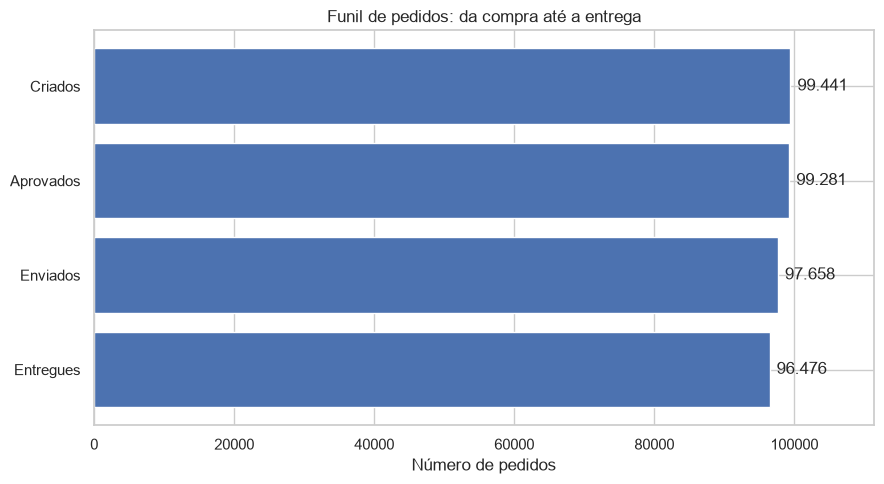

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))

etapas = ["Criados", "Aprovados", "Enviados", "Entregues"]
valores = funil.values

ax.barh(etapas[::-1], valores[::-1], color="#4C72B0")
ax.set_title("Funil de pedidos: da compra até a entrega")
ax.set_xlabel("Número de pedidos")

for i, v in enumerate(valores[::-1]):
    ax.text(v + valores.max() * 0.01, i, f"{v:,}".replace(",", "."), va="center")

ax.set_xlim(0, valores.max() * 1.12)
plt.tight_layout()
plt.savefig("../reports/figures/02_funil_pedidos.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
query_perdas = """
SELECT
    CASE
        WHEN order_approved_at IS NULL            THEN '1. Antes da aprovação'
        WHEN order_delivered_carrier_date IS NULL THEN '2. Aprovado, mas não enviado'
        WHEN order_delivered_customer_date IS NULL THEN '3. Enviado, mas não entregue'
        ELSE '4. Entregue'
    END AS etapa_final,
    order_status,
    COUNT(*) AS pedidos
FROM orders
WHERE order_status IN ('canceled', 'unavailable')
GROUP BY 1, 2
ORDER BY 1, 2;
"""

perdas = pd.read_sql(query_perdas, engine)
perdas

,etapa_final,order_status,pedidos
0,1. Antes da aprovação,canceled,141
1,"2. Aprovado, mas não enviado",canceled,409
2,"2. Aprovado, mas não enviado",unavailable,609
3,"3. Enviado, mas não entregue",canceled,69
4,4. Entregue,canceled,6


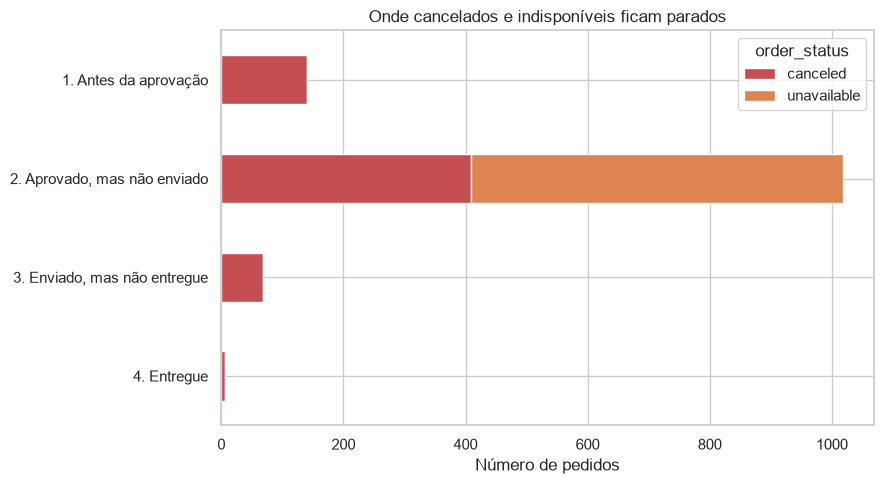

In [ ]:
pivot = (
    perdas.pivot_table(index="etapa_final", columns="order_status",
                       values="pedidos", aggfunc="sum", fill_value=0)
)

ax = pivot.plot(kind="barh", stacked=True, figsize=(9, 5),
                color={"canceled": "#C44E52", "unavailable": "#DD8452"})
ax.set_title("Onde cancelados e indisponíveis ficam parados")
ax.set_xlabel("Número de pedidos")
ax.set_ylabel("")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig("../reports/figures/02_onde_pedidos_param.png", dpi=150, bbox_inches="tight")
plt.show()

O gargalo não está no pagamento nem no transporte, mas no vendedor: o cliente já pagou e o pedido não sai. Como todos os pedidos “indisponíveis” morrem nessa etapa, isso sugere falta de estoque no momento da venda. Ação: monitorar a taxa de cancelamento por vendedor e sinalizar aqueles com perdas recorrentes nessa fase, o que se conecta com a análise de vendedores (pergunta 3 da pasta).